# Assignment 2: Compare GNN Architectures on Cora

## 1. Overview and Objectives
In this assignment, we implement and empirically compare four distinct architectures on the Cora citation benchmark:
1. **MLP** (Feature-only baseline)
2. **GCN** (Symmetric neighborhood averaging)
3. **GraphSAGE** (Sample-and-aggregate with representation concatenation)
4. **GAT** (Multi-head attention over citations)

### Experiments Conducted:
- Dataset inspection (features, citation graph, homophily, and splits).
- 3-seed benchmark tracking Test Accuracy, Macro F1, Training Time, and Parameter Counts.
- Depth vs. Oversmoothing investigation (evaluating embedding cosine similarity collapse).
- Edge removal sweep (0% to 100% edge drop vs. MLP control).
- Qualitative neighborhood error analysis on 5 misclassified test papers.

In [1]:
import os
import sys
sys.path.insert(0, r"D:\gnn-practical-assignments")

import torch
import numpy as np
import matplotlib.pyplot as plt
from assignment2_architectures.dataset_cora import load_cora_dataset, inspect_cora
from assignment2_architectures.train_benchmark import run_architecture_benchmarks
from assignment2_architectures.experiments.depth_and_edges import run_depth_experiment, run_edge_removal_experiment
from assignment2_architectures.error_analysis import analyze_misclassifications
%matplotlib inline
print("Environment initialized.")

c:\Users\hp\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment initialized.


## 2. Dataset Inspection
We inspect the Cora graph topology, node vocabulary sparsity, and scientific topic distribution.

In [2]:
dataset, data = load_cora_dataset()
inspect_cora(data, dataset)

CORA CITATION DATASET INSPECTION
Total Nodes (Research Papers):      2708
Total Undirected Edges (Citations): 5278
Node Features (Vocabulary Words):   1433
Target Classes (Research Topics):   7
Graph Homophily Ratio:              81.00%
Average Node Degree:                3.90
-----------------------------------------------------------------
Splits Distribution:
- Training set nodes:               140 (20 per class)
- Validation set nodes:             500
- Test set nodes:                   1000
-----------------------------------------------------------------
Class label counts across whole graph:
  Class 0: 351 papers
  Class 1: 217 papers
  Class 2: 418 papers
  Class 3: 818 papers
  Class 4: 426 papers
  Class 5: 298 papers
  Class 6: 180 papers


## 3. Architecture Benchmarks (3 Random Seeds)
We evaluate MLP, GCN, GraphSAGE, and GAT under a comparable hyperparameter budget, reporting mean and standard deviation.

In [3]:
benchmark_results = run_architecture_benchmarks(seeds=(42, 123, 999))

RUNNING GNN ARCHITECTURE BENCHMARKS (3 RANDOM SEEDS)

Evaluating MLP (Params: 92,231)...
  Seed 42: Test Acc = 59.50%, Macro F1 = 0.5778, Time = 2.33s
  Seed 123: Test Acc = 57.90%, Macro F1 = 0.5615, Time = 2.37s
  Seed 999: Test Acc = 60.20%, Macro F1 = 0.5822, Time = 2.96s

Evaluating GCN (Params: 92,231)...
  Seed 42: Test Acc = 82.70%, Macro F1 = 0.8136, Time = 3.65s
  Seed 123: Test Acc = 82.10%, Macro F1 = 0.8078, Time = 2.63s
  Seed 999: Test Acc = 82.10%, Macro F1 = 0.8076, Time = 3.03s

Evaluating GraphSAGE (Params: 184,391)...
  Seed 42: Test Acc = 78.50%, Macro F1 = 0.7779, Time = 7.35s
  Seed 123: Test Acc = 79.90%, Macro F1 = 0.7928, Time = 8.13s
  Seed 999: Test Acc = 78.90%, Macro F1 = 0.7835, Time = 7.14s

Evaluating GAT (Params: 92,373)...
  Seed 42: Test Acc = 82.50%, Macro F1 = 0.8103, Time = 9.43s
  Seed 123: Test Acc = 82.60%, Macro F1 = 0.8137, Time = 8.99s
  Seed 999: Test Acc = 82.20%, Macro F1 = 0.8125, Time = 15.13s

Model        | Params   | Test Acc (Mean ±

## 4. Diagnostic 1: GNN Depth vs. Oversmoothing
We vary depth from 2 to 16 layers to observe performance collapse and embedding cosine similarity convergence.


DIAGNOSTIC 1: GNN DEPTH VS. OVERSMOOTHING (GCN)
Depth (Layers)  | Test Accuracy   | Avg Edge Cosine Similarity
----------------------------------------------------------------------
2               | 82.70%          | 0.9593                   
4               | 81.30%          | 0.9764                   
8               | 16.10%          | 0.9365                   
16              | 17.50%          | 0.9879                   


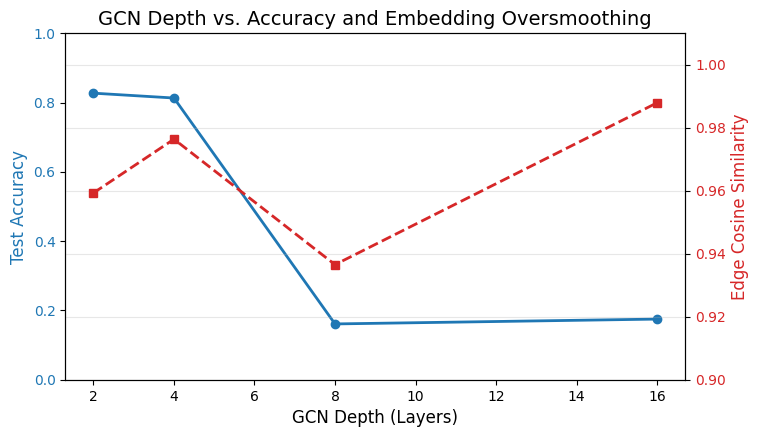

In [4]:
depth_data = run_depth_experiment(depths=(2, 4, 8, 16))

# Plot Depth vs Accuracy and Cosine Similarity
fig, ax1 = plt.subplots(figsize=(8, 4.5))
color = 'tab:blue'
ax1.set_xlabel('GCN Depth (Layers)', fontsize=12)
ax1.set_ylabel('Test Accuracy', color=color, fontsize=12)
ax1.plot(depth_data['depths'], depth_data['accuracies'], marker='o', color=color, linewidth=2, label='Test Accuracy')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1.0)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Edge Cosine Similarity', color=color, fontsize=12)
ax2.plot(depth_data['depths'], depth_data['similarities'], marker='s', color=color, linestyle='--', linewidth=2, label='Cosine Sim')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0.9, 1.01)

plt.title('GCN Depth vs. Accuracy and Embedding Oversmoothing', fontsize=14)
plt.grid(True, alpha=0.3)
plt.show()

## 5. Diagnostic 2: Edge Sparsity Sweep (vs. MLP Control)
We systematically drop edges from 0% to 100% to prove dependency on graph topology.


DIAGNOSTIC 2: EDGE REMOVAL SWEEP (VS MLP CONTROL)
Drop Ratio   | MLP (Control)  | GCN          | GraphSAGE    | GAT         
----------------------------------------------------------------------
        0%   | 59.50%         | 82.70%       | 78.50%       | 82.30%      
       25%   | 59.50%         | 78.40%       | 78.40%       | 80.20%      
       50%   | 59.50%         | 74.30%       | 71.40%       | 76.30%      
       75%   | 59.50%         | 66.10%       | 65.10%       | 68.90%      
      100%   | 59.50%         | 59.60%       | 58.30%       | 58.20%      


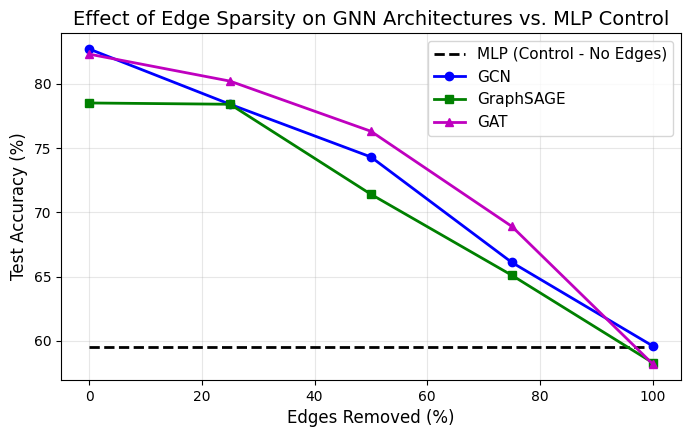

In [5]:
edge_data = run_edge_removal_experiment(drop_ratios=(0.0, 0.25, 0.50, 0.75, 1.0))

plt.figure(figsize=(8, 4.5))
drops = [r * 100 for r in edge_data['drop_ratios']]
plt.plot(drops, [acc * 100 for acc in edge_data['MLP']], 'k--', label='MLP (Control - No Edges)', linewidth=2)
plt.plot(drops, [acc * 100 for acc in edge_data['GCN']], 'b-o', label='GCN', linewidth=2)
plt.plot(drops, [acc * 100 for acc in edge_data['GraphSAGE']], 'g-s', label='GraphSAGE', linewidth=2)
plt.plot(drops, [acc * 100 for acc in edge_data['GAT']], 'm-^', label='GAT', linewidth=2)
plt.xlabel('Edges Removed (%)', fontsize=12)
plt.ylabel('Test Accuracy (%)', fontsize=12)
plt.title('Effect of Edge Sparsity on GNN Architectures vs. MLP Control', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.show()

## 6. Qualitative Neighborhood Error Analysis
We inspect 5 specific test nodes misclassified by GCN to understand neighborhood homophily breakdown.

In [6]:
analyze_misclassifications(num_samples=5)

QUALITATIVE ERROR ANALYSIS: 5 MISCLASSIFIED TEST NODES (Total Test Errors: 173)

--- Case 1: Node ID 1708 ---
True Class:             3 (Probabilistic_Methods)
Predicted Class:        1 (Genetic_Algorithms)
Active Feature Words:   20 / 1433
Total Citations/Degree: 6
Neighbor Class Labels:  [0, 0, 2, 3, 2, 3]
Neighborhood Homophily: 33.3%
Reason for error:       Neighborhood Contamination - majority of citing papers belong to conflicting classes, overpowering the true label signal.

--- Case 2: Node ID 1733 ---
True Class:             2 (Neural_Networks)
Predicted Class:        1 (Genetic_Algorithms)
Active Feature Words:   8 / 1433
Total Citations/Degree: 3
Neighbor Class Labels:  [1, 2, 2]
Neighborhood Homophily: 66.7%
Reason for error:       Ambiguous boundary - conflicting text features despite supportive citations.

--- Case 3: Node ID 1735 ---
True Class:             1 (Genetic_Algorithms)
Predicted Class:        2 (Neural_Networks)
Active Feature Words:   23 / 1433
Total Citation